In [3]:
import pandas as pd
import logging
import time
import matplotlib.pyplot as plt
import talib as ta
import numpy as np
import optuna

from sklearn.feature_selection import VarianceThreshold, RFECV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import train_test_split

from typing import Tuple
from pathlib import Path

from config.settings import ROOT_DIR

DATA_RAW_DIR = ROOT_DIR / "data" / "raw"
DATA_PROC_DIR = ROOT_DIR / "data" / "processed"
SBERBANK_CSV = DATA_RAW_DIR / "sberbank_stock_prices.csv"
GOLD_TIME_SERIES_CSV = DATA_RAW_DIR / "gold_time_series.csv"
OIL_BRENT_TIME_SERIES_CSV = DATA_RAW_DIR / "oil_brent_time_series.csv"
USD_RUB_TIME_SERIES_CSV = DATA_RAW_DIR / "usd_rub_time_series.csv"
CB_RATE_CSV = DATA_RAW_DIR / "cb_rate.csv"

optuna.logging.set_verbosity(optuna.logging.WARNING)

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    handlers=[
        logging.StreamHandler()
    ]
)
logger = logging.getLogger(__name__)

In [4]:
def euro_to_float(x):
    if pd.isna(x):
        return x
    if isinstance(x, (int, float)):
        return float(x)
    try:
        cleaned = str(x).replace('.', '').replace(',', '.')
        return float(cleaned)
    except (ValueError, AttributeError):
        return x  # если не удалось преобразовать, оставляем исходное

In [5]:
def forward_fill_to_date(df: pd.DataFrame, end_date) -> pd.DataFrame:
    df = df.sort_index()
    start_date = df.index.min()
    end_date = pd.to_datetime(end_date)

    if end_date < start_date:
        raise ValueError("end_date должна быть не меньше минимальной даты в индексе")

    full_range = pd.date_range(start=start_date, end=end_date, freq='D')

    df_filled = df.reindex(full_range).ffill()

    return df_filled

In [6]:
def load_sberbank() -> pd.DataFrame:
    df = pd.read_csv(SBERBANK_CSV, delimiter=';', dtype={'<DATE>' : str})
    name_map = {column:column[1:-1].capitalize() for column in df.columns.tolist()}
    df = df.rename(columns=name_map)
    df['Date'] = pd.to_datetime(df['Date'], format='%y%m%d')
    df.set_index('Date', inplace=True)
    return df

In [7]:
def get_time_series(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, delimiter=';')
    df = df.set_index('Date')
    df.index = pd.to_datetime(df.index, dayfirst=True)
    for col in df.select_dtypes(include=['object']).columns:
        df[col] = pd.to_numeric(df[col].apply(euro_to_float), errors='coerce')
    df = forward_fill_to_date(df, '09.01.2025')
    return df

In [8]:
def create_lags(df: pd.DataFrame, column: str, n_lags: int) -> pd.DataFrame:
    new_df = df.copy()
    for lag in range(1, n_lags + 1):
        new_df[f'{column}_lag_{lag}'] = new_df[column].shift(lag)

    return new_df

In [9]:
def generate_features_for_factor(
    df: pd.DataFrame,
    n_lags: int,
    sma_period: int,
    ema_period: int,
    rsi_period: int,
    stoch_fastk: int,
    stoch_slowd: int,
    macd_fast: int,
    macd_slow: int,
    macd_signal: int,
    roc_period: int,
    vol_window: int,
    target_col: str = 'Close'
) -> pd.DataFrame:
    """
    Генерирует признаки для одного фактора на основе цен OHLC.
    Возвращает X (признаки) с индексом, соответствующим дате расчёта.
    Признаки рассчитываются по данным этого же дня (без сдвига).
    """
    df = df.copy()
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)

    close = df[target_col]
    high = df['High'] if 'High' in df.columns else close
    low = df['Low'] if 'Low' in df.columns else close
    open_ = df['Open'] if 'Open' in df.columns else close

    X = pd.DataFrame(index=df.index)

    for lag in range(1, n_lags + 1):
        X[f'close_lag_{lag}'] = close.shift(lag)

    X['high_low'] = high - low
    X['close_open'] = close - open_
    X['high_low_norm'] = (high - low) / close

    X['return_1'] = close.pct_change()
    log_return = np.log(close / close.shift(1))
    X['log_return_1'] = log_return

    X['SMA'] = ta.SMA(close, timeperiod=sma_period)
    X['EMA'] = ta.EMA(close, timeperiod=ema_period)
    X['SMA_EMA_diff'] = X['EMA'] - X['SMA']

    macd, macd_signal_line, macd_hist = ta.MACD(
        close, fastperiod=macd_fast, slowperiod=macd_slow, signalperiod=macd_signal
    )
    X['MACD'] = macd
    X['MACD_signal'] = macd_signal_line
    X['MACD_hist'] = macd_hist

    X['RSI'] = ta.RSI(close, timeperiod=rsi_period)

    slowk, slowd = ta.STOCH(
        high, low, close,
        fastk_period=stoch_fastk,
        slowk_period=3,
        slowk_matype=0,
        slowd_period=stoch_slowd,
        slowd_matype=0
    )
    X['STOCH_K'] = slowk
    X['STOCH_D'] = slowd

    X['Std'] = close.rolling(vol_window).std()
    X['ATR'] = ta.ATR(high, low, close, timeperiod=vol_window)

    X['ROC'] = ta.ROC(close, timeperiod=roc_period)

    X = X.dropna()
    return X

In [10]:
def optimize_factor(
    df_factor: pd.DataFrame,
    target_df: pd.DataFrame,
    factor_name: str,
    target_col: str = 'Close',
    n_trials: int = 100,
    n_splits: int = 5
):
    """
    Оптимизирует параметры индикаторов для фактора factor_name.
    Признаки строятся из df_factor, целевая переменная — target_col из target_df (цена закрытия).
    Для прогноза используется принцип: признаки на день t-1 предсказывают цену на день t.
    """
    logger.info(f"Начало оптимизации для фактора {factor_name}")

    common_dates = df_factor.index.intersection(target_df.index)
    df_factor = df_factor.loc[common_dates]
    target_df = target_df.loc[common_dates]
    logger.info(f"Общих дат: {len(common_dates)}")

    y_target = target_df[target_col]

    def objective(trial):
        params = {
            'n_lags': trial.suggest_int('n_lags', 4, 6),
            'sma_period': trial.suggest_int('sma_period', 5, 14),
            'ema_period': trial.suggest_int('ema_period', 5, 14),
            'rsi_period': trial.suggest_int('rsi_period', 5, 20),
            'stoch_fastk': trial.suggest_int('stoch_fastk', 5, 20),
            'stoch_slowd': trial.suggest_int('stoch_slowd', 3, 10),
            'macd_fast': trial.suggest_int('macd_fast', 8, 20),
            'macd_slow': trial.suggest_int('macd_slow', 20, 30),
            'macd_signal': trial.suggest_int('macd_signal', 5, 15),
            'roc_period': trial.suggest_int('roc_period', 3, 15),
            'vol_window': trial.suggest_int('vol_window', 5, 15)
        }

        X = generate_features_for_factor(
            df=df_factor,
            target_col=target_col,
            **params
        )
        X_shifted = X.shift(1)

        combined = pd.concat([X_shifted, y_target], axis=1).dropna()
        if combined.shape[0] < 50:
            return 1.0

        X_clean = combined.iloc[:, :-1]
        y_clean = combined.iloc[:, -1]

        X_train, X_test, y_train, y_test = train_test_split(
            X_clean, y_clean, test_size=0.2, shuffle=False
        )

        tscv = TimeSeriesSplit(n_splits=n_splits)
        model = GradientBoostingRegressor(random_state=42, n_estimators=50)
        mape_scores = []

        for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train), 1):
            X_train_l, X_val = X_train.iloc[train_idx], X_train.iloc[test_idx]
            y_train_l, y_val = y_train.iloc[train_idx], y_train.iloc[test_idx]

            if len(y_train) < 10 or len(y_test) < 10:
                continue

            model.fit(X_train_l, y_train_l)
            y_pred = model.predict(X_val)
            mape = mean_absolute_percentage_error(y_val, y_pred)
            mape_scores.append(mape)

        if not mape_scores:
            return 1.0
        mean_mape = np.mean(mape_scores)
        logger.debug(f"Trial {trial.number}: MAPE = {mean_mape:.4f}")
        return mean_mape

    study = optuna.create_study(direction='minimize', study_name=factor_name, sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

    logger.info(f"Оптимизация для {factor_name} завершена")
    logger.info(f"Лучшее значение MAPE: {study.best_value:.4f}")
    logger.info("Лучшие параметры:")
    for k, v in study.best_params.items():
        logger.info(f"  {k}: {v}")

    return study.best_params

In [11]:
TARGET_COLUMN = 'Close'

stock_data = load_sberbank()
sber_df = forward_fill_to_date(stock_data, '09.01.2025')
gold_df = get_time_series(GOLD_TIME_SERIES_CSV)
oil_df = get_time_series(OIL_BRENT_TIME_SERIES_CSV)
usd_rub_df = get_time_series(USD_RUB_TIME_SERIES_CSV)

best_sber = optimize_factor(sber_df, sber_df, 'SBER', target_col=TARGET_COLUMN, n_trials=100)
best_gold = optimize_factor(gold_df, sber_df, 'GOLD', target_col=TARGET_COLUMN, n_trials=100)
best_oil = optimize_factor(oil_df, sber_df, 'OIL', target_col=TARGET_COLUMN, n_trials=100)
best_usdrub = optimize_factor(usd_rub_df, sber_df, 'USDRUB', target_col=TARGET_COLUMN, n_trials=100)

# Сводная таблица
results = pd.DataFrame(
    [best_sber, best_gold, best_oil, best_usdrub],
    index=['SBER', 'GOLD', 'OIL', 'USDRUB']
)
print("\nСводная таблица оптимальных параметров:")
print(results)

2026-03-06 18:45:50,743 - INFO - Начало оптимизации для фактора SBER
2026-03-06 18:45:50,746 - INFO - Общих дат: 1827


  0%|          | 0/100 [00:00<?, ?it/s]

2026-03-06 18:48:08,426 - INFO - Оптимизация для SBER завершена
2026-03-06 18:48:08,429 - INFO - Лучшее значение MAPE: 0.1335
2026-03-06 18:48:08,433 - INFO - Лучшие параметры:
2026-03-06 18:48:08,435 - INFO -   n_lags: 6
2026-03-06 18:48:08,436 - INFO -   sma_period: 8
2026-03-06 18:48:08,438 - INFO -   ema_period: 13
2026-03-06 18:48:08,440 - INFO -   rsi_period: 9
2026-03-06 18:48:08,440 - INFO -   stoch_fastk: 13
2026-03-06 18:48:08,442 - INFO -   stoch_slowd: 3
2026-03-06 18:48:08,443 - INFO -   macd_fast: 9
2026-03-06 18:48:08,444 - INFO -   macd_slow: 20
2026-03-06 18:48:08,446 - INFO -   macd_signal: 15
2026-03-06 18:48:08,447 - INFO -   roc_period: 8
2026-03-06 18:48:08,449 - INFO -   vol_window: 8
2026-03-06 18:48:08,453 - INFO - Начало оптимизации для фактора GOLD
2026-03-06 18:48:08,459 - INFO - Общих дат: 1827


  0%|          | 0/100 [00:00<?, ?it/s]

2026-03-06 18:50:28,783 - INFO - Оптимизация для GOLD завершена
2026-03-06 18:50:28,785 - INFO - Лучшее значение MAPE: 0.3990
2026-03-06 18:50:28,786 - INFO - Лучшие параметры:
2026-03-06 18:50:28,788 - INFO -   n_lags: 6
2026-03-06 18:50:28,791 - INFO -   sma_period: 14
2026-03-06 18:50:28,793 - INFO -   ema_period: 13
2026-03-06 18:50:28,795 - INFO -   rsi_period: 11
2026-03-06 18:50:28,796 - INFO -   stoch_fastk: 15
2026-03-06 18:50:28,798 - INFO -   stoch_slowd: 5
2026-03-06 18:50:28,799 - INFO -   macd_fast: 9
2026-03-06 18:50:28,800 - INFO -   macd_slow: 22
2026-03-06 18:50:28,801 - INFO -   macd_signal: 6
2026-03-06 18:50:28,802 - INFO -   roc_period: 4
2026-03-06 18:50:28,802 - INFO -   vol_window: 11
2026-03-06 18:50:28,804 - INFO - Начало оптимизации для фактора OIL
2026-03-06 18:50:28,812 - INFO - Общих дат: 1827


  0%|          | 0/100 [00:00<?, ?it/s]

2026-03-06 18:52:33,688 - INFO - Оптимизация для OIL завершена
2026-03-06 18:52:33,690 - INFO - Лучшее значение MAPE: 0.4133
2026-03-06 18:52:33,692 - INFO - Лучшие параметры:
2026-03-06 18:52:33,693 - INFO -   n_lags: 4
2026-03-06 18:52:33,695 - INFO -   sma_period: 14
2026-03-06 18:52:33,696 - INFO -   ema_period: 9
2026-03-06 18:52:33,696 - INFO -   rsi_period: 18
2026-03-06 18:52:33,699 - INFO -   stoch_fastk: 7
2026-03-06 18:52:33,700 - INFO -   stoch_slowd: 5
2026-03-06 18:52:33,700 - INFO -   macd_fast: 20
2026-03-06 18:52:33,701 - INFO -   macd_slow: 28
2026-03-06 18:52:33,702 - INFO -   macd_signal: 5
2026-03-06 18:52:33,703 - INFO -   roc_period: 11
2026-03-06 18:52:33,705 - INFO -   vol_window: 12
2026-03-06 18:52:33,709 - INFO - Начало оптимизации для фактора USDRUB
2026-03-06 18:52:33,715 - INFO - Общих дат: 1827


  0%|          | 0/100 [00:00<?, ?it/s]

2026-03-06 18:54:45,215 - INFO - Оптимизация для USDRUB завершена
2026-03-06 18:54:45,216 - INFO - Лучшее значение MAPE: 0.3678
2026-03-06 18:54:45,218 - INFO - Лучшие параметры:
2026-03-06 18:54:45,221 - INFO -   n_lags: 5
2026-03-06 18:54:45,222 - INFO -   sma_period: 12
2026-03-06 18:54:45,223 - INFO -   ema_period: 13
2026-03-06 18:54:45,224 - INFO -   rsi_period: 15
2026-03-06 18:54:45,225 - INFO -   stoch_fastk: 13
2026-03-06 18:54:45,227 - INFO -   stoch_slowd: 4
2026-03-06 18:54:45,228 - INFO -   macd_fast: 19
2026-03-06 18:54:45,229 - INFO -   macd_slow: 20
2026-03-06 18:54:45,229 - INFO -   macd_signal: 6
2026-03-06 18:54:45,230 - INFO -   roc_period: 15
2026-03-06 18:54:45,230 - INFO -   vol_window: 13



Сводная таблица оптимальных параметров:
        n_lags  sma_period  ema_period  rsi_period  stoch_fastk  stoch_slowd  \
SBER         6           8          13           9           13            3   
GOLD         6          14          13          11           15            5   
OIL          4          14           9          18            7            5   
USDRUB       5          12          13          15           13            4   

        macd_fast  macd_slow  macd_signal  roc_period  vol_window  
SBER            9         20           15           8           8  
GOLD            9         22            6           4          11  
OIL            20         28            5          11          12  
USDRUB         19         20            6          15          13  


In [12]:
def generate_external_features(
    ext_df: pd.DataFrame,
    name_prefix: str,
    n_lags: int = 3,
    ema_period: int = 9,
    sma_period: int = 11,
    rsi_period: int = 9,
    stoch_fastk: int = 14,
    stoch_slowd: int = 3,
    macd_fast: int = 12,
    macd_slow: int = 26,
    macd_signal: int = 9,
    roc_period: int = 5,
    vol_window: int = 11,
) -> pd.DataFrame:
    """
    Генерирует расширенный набор признаков для одного внешнего фактора
    с возможностью настройки всех параметров индикаторов.
    """
    df = ext_df.copy()
    close = df['Close']
    high = df['High'] if 'High' in df.columns else close
    low = df['Low'] if 'Low' in df.columns else close
    open_ = df['Open'] if 'Open' in df.columns else close

    out = pd.DataFrame(index=df.index)

    for k in range(1, n_lags + 1):
        out[f"{name_prefix}_lag_{k}"] = close.shift(k)

    out[f"{name_prefix}_Open_lag_1"] = open_.shift(1)
    out[f"{name_prefix}_High_lag_1"] = high.shift(1)
    out[f"{name_prefix}_Low_lag_1"] = low.shift(1)

    out[f"{name_prefix}_return_1"] = close.pct_change()
    out[f"{name_prefix}_log_return_1"] = np.log(close / close.shift(1))

    out[f"{name_prefix}_EMA_{ema_period}"] = ta.EMA(close, timeperiod=ema_period)
    out[f"{name_prefix}_SMA_{sma_period}"] = ta.SMA(close, timeperiod=sma_period)
    out[f"{name_prefix}_EMA_SMA_diff"] = out[f"{name_prefix}_EMA_{ema_period}"] - out[f"{name_prefix}_SMA_{sma_period}"]

    macd, macd_signal_line, macd_hist = ta.MACD(
        close, fastperiod=macd_fast, slowperiod=macd_slow, signalperiod=macd_signal
    )
    out[f"{name_prefix}_MACD"] = macd
    out[f"{name_prefix}_MACD_signal"] = macd_signal_line
    out[f"{name_prefix}_MACD_hist"] = macd_hist

    out[f"{name_prefix}_RSI_{rsi_period}"] = ta.RSI(close, timeperiod=rsi_period)
    out[f"{name_prefix}_ROC_{roc_period}"] = ta.ROC(close, timeperiod=roc_period)
    
    slowk, slowd = ta.STOCH(
        high, low, close,
        fastk_period=stoch_fastk,
        slowk_period=3,
        slowk_matype=0,
        slowd_period=stoch_slowd,
        slowd_matype=0
    )
    out[f"{name_prefix}_Stoch_K"] = slowk
    out[f"{name_prefix}_Stoch_D"] = slowd
        
    out[f"{name_prefix}_Std_{vol_window}"] = close.rolling(vol_window).std()
    out[f"{name_prefix}_ATR"] = ta.ATR(high, low, close, timeperiod=vol_window)

    out[f"{name_prefix}_intraday_range"] = high - low
    out[f"{name_prefix}_relative_range"] = (high - low) / close
    out[f"{name_prefix}_intraday_return"] = close - open_

    out = out.replace([np.inf, -np.inf], np.nan)
    out.dropna(inplace=True)

    return out

In [13]:
def create_ta_features(
    df: pd.DataFrame,
    n_lags: int = 4,
    ema_period: int = 9,
    sma_period: int = 11,
    rsi_period: int = 9,
    stoch_fastk: int = 14,
    stoch_slowd: int = 3,
    macd_fast: int = 12,
    macd_slow: int = 26,
    macd_signal: int = 9,
    roc_period: int = 5,
    vol_window: int = 11,
    target: str = "Close",
    external_config = None,
    optimized_params = None
) -> pd.DataFrame:
    """
    Основная функция генерации признаков.
    Если use_optimized_params=True и передан optimized_params, параметры
    для каждого фактора берутся из этого словаря.
    """
    logger.info("=" * 60)
    logger.info("НАЧАЛО ГЕНЕРАЦИИ ПРИЗНАКОВ")
    logger.info("=" * 60)

    out = df.copy()
    initial_rows = len(out)
    initial_cols = out.shape[1]
    logger.info(f"Исходный датафрейм: строк = {initial_rows}, колонок = {initial_cols}")

    for col in ['Ticker', 'Per', 'Time']:
        if col in out.columns:
            out.drop(columns=col, inplace=True)
            logger.info(f"Удалена служебная колонка: {col}")

    if external_config is not None:
        logger.info("--- Этап 1: Внешние факторы ---")
        for idx, cfg in enumerate(external_config, 1):
            name = cfg['name']
            ext_data = cfg['data'].copy()
            logger.info(f"  Обработка внешнего фактора {idx}: {name}")

            params = optimized_params[name]
            ext_n_lags = params.get('n_lags', n_lags)
            ext_ema = params.get('ema_period', ema_period)
            ext_sma = params.get('sma_period', sma_period)
            ext_rsi = params.get('rsi_period', rsi_period)
            ext_stoch_fastk = params.get('stoch_fastk', stoch_fastk)
            ext_stoch_slowd = params.get('stoch_slowd', stoch_slowd)
            ext_macd_fast = params.get('macd_fast', macd_fast)
            ext_macd_slow = params.get('macd_slow', macd_slow)
            ext_macd_signal = params.get('macd_signal', macd_signal)
            ext_roc = params.get('roc_period', roc_period)
            ext_vol = params.get('vol_window', vol_window)

            ext_features = generate_external_features(
                ext_df=ext_data,
                name_prefix=name,
                n_lags=ext_n_lags,
                ema_period=ext_ema,
                sma_period=ext_sma,
                rsi_period=ext_rsi,
                stoch_fastk=ext_stoch_fastk,
                stoch_slowd=ext_stoch_slowd,
                macd_fast=ext_macd_fast,
                macd_slow=ext_macd_slow,
                macd_signal=ext_macd_signal,
                roc_period=ext_roc,
                vol_window=ext_vol,
            )

            ext_features_shifted = ext_features.shift(1)
            n_new = ext_features_shifted.shape[1]
            logger.info(f"    Сгенерировано {n_new} признаков для {name}")

            before = out.shape[1]
            out = out.join(ext_features_shifted, how='left')
            after = out.shape[1]
            logger.info(f"    Добавлено {after - before} признаков (всего {after})")

    logger.info("--- Этап 2: Лаговые признаки (акции) ---")
    before = out.shape[1]
    for k in range(1, n_lags + 1):
        out[f"{target}_lag_{k}"] = out[target].shift(k)

    out["Open_lag_1"] = out["Open"].shift(1)
    out["High_lag_1"] = out["High"].shift(1)
    out["Low_lag_1"] = out["Low"].shift(1)
    logger.info(f"  Добавлено лаговых признаков: {out.shape[1] - before}")

    c1 = out[f"{target}_lag_1"]
    h1 = out["High_lag_1"]
    l1 = out["Low_lag_1"]
    o1 = out["Open_lag_1"]

    logger.info("--- Этап 3: Доходности (акции) ---")
    before = out.shape[1]
    out["Log_return_1"] = np.log(c1 / out[f"{target}_lag_2"])
    out["Return_1"] = c1.pct_change()
    logger.info(f"  Добавлено признаков доходности: {out.shape[1] - before}")

    logger.info("--- Этап 4: Трендовые индикаторы (акции) ---")
    before = out.shape[1]

    p = optimized_params['SBER']
    ema_p = p.get('ema_period', ema_period)
    sma_p = p.get('sma_period', sma_period)
    macd_f = p.get('macd_fast', macd_fast)
    macd_s = p.get('macd_slow', macd_slow)
    macd_sig = p.get('macd_signal', macd_signal)
    vol_w = p.get('vol_window', vol_window)
    rsi_p = p.get('rsi_period', rsi_period)
    roc_p = p.get('roc_period', roc_period)
    stoch_f = p.get('stoch_fastk', stoch_fastk)
    stoch_sd = p.get('stoch_slowd', stoch_slowd)

    out[f"EMA_{ema_p}"] = ta.EMA(c1, timeperiod=ema_p)
    out[f"SMA_{sma_p}"] = ta.SMA(c1, timeperiod=sma_p)
    out["EMA_SMA_diff"] = out[f"EMA_{ema_p}"] - out[f"SMA_{sma_p}"]

    macd, macd_signal_line, macd_hist = ta.MACD(c1, fastperiod=macd_f, slowperiod=macd_s, signalperiod=macd_sig)
    out["MACD"] = macd
    out["MACD_signal"] = macd_signal_line
    out["MACD_hist"] = macd_hist
    logger.info(f"  Добавлено трендовых индикаторов: {out.shape[1] - before}")

    logger.info("--- Этап 5: Осцилляторы (акции) ---")
    before = out.shape[1]
    out[f"RSI_{rsi_p}"] = ta.RSI(c1, timeperiod=rsi_p)
    out[f"ROC_{roc_p}"] = ta.ROC(c1, timeperiod=roc_p)
    out["Stoch_K"], out["Stoch_D"] = ta.STOCH(h1, l1, c1, fastk_period=stoch_f, slowk_period=3, slowd_period=stoch_sd)
    logger.info(f"  Добавлено осцилляторов: {out.shape[1] - before}")

    logger.info("--- Этап 6: Волатильность (акции) ---")
    before = out.shape[1]
    out[f"Std_{vol_w}"] = c1.rolling(vol_w).std()
    out["ATR"] = ta.ATR(h1, l1, c1, timeperiod=vol_w)
    logger.info(f"  Добавлено индикаторов волатильности: {out.shape[1] - before}")

    logger.info("--- Этап 7: Внутридневные характеристики (акции) ---")
    before = out.shape[1]
    out["Intraday_range"] = h1 - l1
    out["Intraday_return"] = c1 - o1
    out["Relative_range"] = (h1 - l1) / c1
    logger.info(f"  Добавлено внутридневных признаков: {out.shape[1] - before}")

    logger.info("--- Этап 8: Очистка ---")
    for col in ["Open", "High", "Low"]:
        if col in out.columns:
            out.drop(columns=col, inplace=True)
            logger.info(f"  Удалена исходная колонка: {col}")

    before_dropna = len(out)
    out = out.replace([np.inf, -np.inf], np.nan)
    out.dropna(inplace=True)
    dropped = before_dropna - len(out)
    logger.info(f"  Удалено строк с пропусками: {dropped} (осталось {len(out)})")

    logger.info("=" * 60)
    logger.info("ИТОГ ГЕНЕРАЦИИ ПРИЗНАКОВ")
    logger.info(f"  Итоговое количество признаков: {out.shape[1]}")
    logger.info(f"  Итоговое количество строк: {out.shape[0]}")
    logger.info("=" * 60)

    return out

In [14]:
TARGET_COLUMN = 'Close'

optimized_params = {
    'SBER': best_sber,
    'GOLD': best_gold,
    'OIL': best_oil,
    'USDRUB': best_usdrub
}

external_config = [
    {'name': 'Gold', 'data': gold_df},
    {'name': 'Oil', 'data': oil_df},
    {'name': 'USDRUB', 'data': usd_rub_df},
]

# Генерируем полный набор признаков
df_features = create_ta_features(
    df=sber_df,
    target='Close',
    external_config=[
        {'name': 'GOLD', 'data': gold_df},
        {'name': 'OIL', 'data': oil_df},
        {'name': 'USDRUB', 'data': usd_rub_df}
    ],
    optimized_params=optimized_params,
)

2026-03-06 18:54:45,385 - INFO - ============================================================
2026-03-06 18:54:45,387 - INFO - НАЧАЛО ГЕНЕРАЦИИ ПРИЗНАКОВ
2026-03-06 18:54:45,388 - INFO - ============================================================
2026-03-06 18:54:45,392 - INFO - Исходный датафрейм: строк = 1827, колонок = 7
2026-03-06 18:54:45,396 - INFO - Удалена служебная колонка: Ticker
2026-03-06 18:54:45,398 - INFO - Удалена служебная колонка: Per
2026-03-06 18:54:45,402 - INFO - Удалена служебная колонка: Time
2026-03-06 18:54:45,404 - INFO - --- Этап 1: Внешние факторы ---
2026-03-06 18:54:45,407 - INFO -   Обработка внешнего фактора 1: GOLD
2026-03-06 18:54:45,430 - INFO -     Сгенерировано 26 признаков для GOLD
2026-03-06 18:54:45,434 - INFO -     Добавлено 26 признаков (всего 30)
2026-03-06 18:54:45,438 - INFO -   Обработка внешнего фактора 2: OIL
2026-03-06 18:54:45,478 - INFO -     Сгенерировано 24 признаков для OIL
2026-03-06 18:54:45,485 - INFO -     Добавлено 24 признак

In [15]:
df_features.head()

,Close,GOLD_lag_1,GOLD_lag_2,GOLD_lag_3,GOLD_lag_4,GOLD_lag_5,GOLD_lag_6,GOLD_Open_lag_1,GOLD_High_lag_1,GOLD_Low_lag_1,...,MACD_hist,RSI_9,ROC_8,Stoch_K,Stoch_D,Std_8,ATR,Intraday_range,Intraday_return,Relative_range
2020-10-05,208.89,1903.8,1903.8,1912.3,1891.3,1898.7,1872.8,1907.0,1919.0,1893.0,...,-4.917303,19.671157,-8.517350,8.928129,22.676108,9.865239,6.043361,4.89,-1.60,0.023420
2020-10-06,211.18,1903.8,1903.8,1903.8,1912.3,1891.3,1898.7,1907.0,1919.0,1893.0,...,-4.895168,19.995603,-8.477918,9.101562,12.823176,10.104881,5.659191,2.97,-0.71,0.014218
2020-10-07,210.60,1916.1,1903.8,1903.8,1903.8,1912.3,1891.3,1906.7,1920.0,1887.7,...,-4.432020,28.286763,-7.632419,12.448234,10.159309,9.395551,5.531792,4.64,2.18,0.021972
2020-10-08,207.97,1904.8,1916.1,1903.8,1903.8,1903.8,1912.3,1913.7,1922.0,1875.1,...,-3.965803,27.475444,-6.599255,15.089181,12.212993,8.707450,5.294068,3.63,-0.71,0.017236
2020-10-09,205.38,1886.8,1904.8,1916.1,1903.8,1903.8,1903.8,1879.9,1897.4,1873.2,...,-3.699984,23.968499,-9.238893,13.997821,13.845079,6.430721,5.153560,4.17,-3.24,0.020051


In [16]:
df_features.columns.tolist()

['Close',
 'GOLD_lag_1',
 'GOLD_lag_2',
 'GOLD_lag_3',
 'GOLD_lag_4',
 'GOLD_lag_5',
 'GOLD_lag_6',
 'GOLD_Open_lag_1',
 'GOLD_High_lag_1',
 'GOLD_Low_lag_1',
 'GOLD_return_1',
 'GOLD_log_return_1',
 'GOLD_EMA_13',
 'GOLD_SMA_14',
 'GOLD_EMA_SMA_diff',
 'GOLD_MACD',
 'GOLD_MACD_signal',
 'GOLD_MACD_hist',
 'GOLD_RSI_11',
 'GOLD_ROC_4',
 'GOLD_Stoch_K',
 'GOLD_Stoch_D',
 'GOLD_Std_11',
 'GOLD_ATR',
 'GOLD_intraday_range',
 'GOLD_relative_range',
 'GOLD_intraday_return',
 'OIL_lag_1',
 'OIL_lag_2',
 'OIL_lag_3',
 'OIL_lag_4',
 'OIL_Open_lag_1',
 'OIL_High_lag_1',
 'OIL_Low_lag_1',
 'OIL_return_1',
 'OIL_log_return_1',
 'OIL_EMA_9',
 'OIL_SMA_14',
 'OIL_EMA_SMA_diff',
 'OIL_MACD',
 'OIL_MACD_signal',
 'OIL_MACD_hist',
 'OIL_RSI_18',
 'OIL_ROC_11',
 'OIL_Stoch_K',
 'OIL_Stoch_D',
 'OIL_Std_12',
 'OIL_ATR',
 'OIL_intraday_range',
 'OIL_relative_range',
 'OIL_intraday_return',
 'USDRUB_lag_1',
 'USDRUB_lag_2',
 'USDRUB_lag_3',
 'USDRUB_lag_4',
 'USDRUB_lag_5',
 'USDRUB_Open_lag_1',
 'USDRUB_

In [17]:
df_features.describe()

,Close,GOLD_lag_1,GOLD_lag_2,GOLD_lag_3,GOLD_lag_4,GOLD_lag_5,GOLD_lag_6,GOLD_Open_lag_1,GOLD_High_lag_1,GOLD_Low_lag_1,...,MACD_hist,RSI_9,ROC_8,Stoch_K,Stoch_D,Std_8,ATR,Intraday_range,Intraday_return,Relative_range
count,1793.000000,1793.000000,1793.000000,1793.000000,1793.00000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,...,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000
mean,251.056520,2139.540290,2138.664384,2137.793218,2136.91034,2136.053118,2135.190151,2138.685220,2154.390931,2123.423134,...,-0.008631,54.002109,0.324788,56.550775,56.557777,3.787111,6.337551,6.195254,0.096999,0.028510
std,68.459334,484.511618,483.515838,482.514153,481.51453,480.568254,479.649559,483.094362,488.692348,478.449494,...,2.361877,18.566014,5.562328,27.770069,27.021713,3.699292,5.137828,6.211721,4.571357,0.041818
min,101.500000,1623.600000,1623.600000,1623.600000,1623.60000,1623.600000,1623.600000,1621.500000,1640.200000,1613.000000,...,-21.070695,6.672406,-52.415581,0.993804,4.255113,0.000000,1.454801,0.410000,-54.400000,0.001284
25%,218.600000,1812.400000,1812.400000,1812.400000,1812.40000,1812.400000,1812.400000,1812.300000,1823.600000,1800.800000,...,-1.038763,41.591273,-1.720362,31.332061,32.166618,1.849270,4.065439,3.210000,-1.910000,0.012524
50%,270.640000,1925.100000,1924.300000,1924.100000,1924.10000,1924.100000,1924.100000,1927.400000,1937.300000,1915.900000,...,-0.021432,54.226245,0.334395,60.133630,60.053351,2.935355,5.130960,4.610000,0.030000,0.018775
75%,304.100000,2357.000000,2357.000000,2357.000000,2356.50000,2354.700000,2354.700000,2357.900000,2374.500000,2332.100000,...,1.055669,67.149697,2.539336,82.081465,81.159068,4.633189,6.635115,7.050000,2.170000,0.028953
max,387.600000,3501.800000,3501.800000,3501.800000,3501.80000,3501.800000,3501.800000,3502.800000,3509.900000,3451.700000,...,8.313486,95.816505,26.235741,99.953315,99.586092,51.194147,38.411395,97.950000,28.280000,0.741035


In [18]:
df_features.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1793 entries, 2020-10-05 to 2025-09-01
Freq: D
Data columns (total 100 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Close                   1793 non-null   float64
 1   GOLD_lag_1              1793 non-null   float64
 2   GOLD_lag_2              1793 non-null   float64
 3   GOLD_lag_3              1793 non-null   float64
 4   GOLD_lag_4              1793 non-null   float64
 5   GOLD_lag_5              1793 non-null   float64
 6   GOLD_lag_6              1793 non-null   float64
 7   GOLD_Open_lag_1         1793 non-null   float64
 8   GOLD_High_lag_1         1793 non-null   float64
 9   GOLD_Low_lag_1          1793 non-null   float64
 10  GOLD_return_1           1793 non-null   float64
 11  GOLD_log_return_1       1793 non-null   float64
 12  GOLD_EMA_13             1793 non-null   float64
 13  GOLD_SMA_14             1793 non-null   float64
 14  GOLD_EMA_SMA_

In [19]:
X, y = df_features.drop(TARGET_COLUMN, axis=1), df_features[TARGET_COLUMN]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [20]:
def variance_filter(X: pd.DataFrame, threshold: float = 0.01) -> pd.DataFrame:
    """
    Удаляет признаки с низкой дисперсией.
    
    Parameters
    ----------
    X : pd.DataFrame
        Исходные признаки.
    threshold : float, default=0.01
        Порог дисперсии (после стандартизации).
    
    Returns
    -------
    pd.DataFrame
        Отфильтрованный DataFrame.
    """
    logger.info(f"VarianceThreshold: порог = {threshold}")
    start = time.time()
    
    selector = VarianceThreshold(threshold=threshold)
    selector.fit(X)
    selected_features = X.columns[selector.get_support()]
    
    elapsed = time.time() - start
    logger.info(f"VarianceThreshold завершён за {elapsed:.2f} сек. "
                f"Признаков осталось: {len(selected_features)} из {X.shape[1]}")
    
    return X[selected_features]

In [21]:
def permutation_importance_selection(
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int = 5,
    plot: bool = True,
    save_plot: bool = True
) -> pd.DataFrame:
    """
    Оценивает важность признаков с помощью перестановочной важности
    на кросс-валидации TimeSeriesSplit.
    
    Parameters
    ----------
    X : pd.DataFrame
        Признаки.
    y : pd.Series
        Целевая переменная.
    n_splits : int, default=5
        Число разбиений для TimeSeriesSplit.
    plot : bool, default=True
        Построить график важности.
    save_plot : bool, default=True
        Сохранить график в файл.
    
    Returns
    -------
    pd.DataFrame
        Таблица с признаками и их усреднённой важностью.
    """
    logger.info("Permutation Importance: старт")
    start = time.time()
    
    model = GradientBoostingRegressor(random_state=42)
    tscv = TimeSeriesSplit(n_splits=n_splits)
    
    importances_list = []
    
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X), 1):
        logger.debug(f"  Fold {fold}/{n_splits}")
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        model.fit(X_train, y_train)
        
        result = permutation_importance(
            model,
            X_test,
            y_test,
            n_repeats=10,
            random_state=42,
            scoring="neg_mean_absolute_percentage_error"
        )
        importances_list.append(result.importances_mean)
    
    importances_mean = np.mean(importances_list, axis=0)
    
    elapsed = time.time() - start
    logger.info(f"Permutation Importance завершён за {elapsed:.2f} сек.")
    
    importance_df = pd.DataFrame({
        "feature": X.columns,
        "importance": importances_mean
    }).sort_values(by="importance", ascending=False).reset_index(drop=True)
    
    return importance_df

In [22]:
def select_top_features(
    X: pd.DataFrame,
    importance_df: pd.DataFrame,
    top_n: int = 30
) -> pd.DataFrame:
    """
    Оставляет только top_n признаков с наибольшей важностью.
    """
    logger.info(f"Отбор топ-{top_n} признаков")
    selected_features = importance_df.head(top_n)["feature"].values
    logger.debug(f"Отобранные признаки: {list(selected_features)}")
    return X[selected_features]

In [23]:
def rfecv_selection(
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int = 5,
    min_features: int = 10,
    plot: bool = True,
    save_plot: bool = True
):
    """
    Рекурсивное исключение признаков с кросс-валидацией (RFECV).
    
    Parameters
    ----------
    X, y : данные
    n_splits : число разбиений TimeSeriesSplit
    min_features : минимальное число признаков для отбора
    plot : построить график зависимости качества от числа признаков
    save_plot : сохранить график
    
    Returns
    -------
    selected_features : индексы отобранных признаков
    rfecv : обученный объект RFECV
    """
    logger.info("RFECV: старт")
    start = time.perf_counter()
    
    model = GradientBoostingRegressor(random_state=42)
    tscv = TimeSeriesSplit(n_splits=n_splits)
    
    rfecv = RFECV(
        estimator=model,
        step=1,
        cv=tscv,
        scoring="neg_mean_absolute_percentage_error",
        min_features_to_select=min_features,
        n_jobs=-1
    )
    
    rfecv.fit(X, y)
    
    elapsed = time.perf_counter() - start
    logger.info(f"RFECV завершён за {elapsed:.2f} сек.")
    logger.info(f"Оптимальное число признаков: {rfecv.n_features_}")
    
    return rfecv.support_, rfecv

In [24]:
def full_feature_selection_pipeline(
    df_features: pd.DataFrame,
    target_col: str = "Target",
    variance_threshold: float = 0.01,
    top_n: int = 30,
    n_splits: int = 5,
    min_features_rfecv: int = 10,
    plot_importance: bool = True,
    plot_rfecv: bool = True,
    save_plots: bool = True
) -> Tuple[np.ndarray, pd.DataFrame, RFECV, dict]:
    logger.info("=" * 60)
    logger.info("ЗАПУСК ПОЛНОГО ПАЙПЛАЙНА ОТБОРА ПРИЗНАКОВ")
    logger.info("=" * 60)
    
    X = df_features.drop(columns=[target_col])
    y = df_features[target_col]
    
    # Шаг 1
    X_variance = variance_filter(X, threshold=variance_threshold)
    after_variance = X_variance.columns.tolist()
    logger.info(f"После VarianceThreshold осталось: {len(after_variance)}")
    
    # Шаг 2: Permutation Importance
    importance_df = permutation_importance_selection(
        X_variance, y, n_splits=n_splits,
        plot=plot_importance, save_plot=save_plots
    )
    
    # Шаг 3: Отбор top-N
    X_top = select_top_features(X_variance, importance_df, top_n=top_n)
    after_topn = X_top.columns.tolist()
    logger.info(f"После отбора top-{top_n} осталось: {len(after_topn)}")
    
    # Шаг 4: RFECV
    final_mask, rfecv = rfecv_selection(
        X_top, y,
        n_splits=n_splits,
        min_features=min_features_rfecv,
        plot=plot_rfecv, save_plot=save_plots
    )
    
    final_features = X_top.columns[final_mask].tolist()
    logger.info(f"После RFECV финальных признаков: {len(final_features)}")
    
    stage_features = {
        'after_variance': after_variance,
        'after_topn': after_topn,
        'after_rfecv': final_features
    }
    
    return final_features, importance_df, rfecv, stage_features

In [25]:
def compare_windows_selection(
    df_features: pd.DataFrame,
    target_col: str = "Target",
    window_sizes: Tuple[int, ...] = (252, 504, 756),
    variance_threshold: float = 0.01,
    top_n: int = 30,
    n_splits: int = 5,
    min_features_rfecv: int = 20,
    plot: bool = True,
    save_plot: bool = False,
    selection_threshold: float = 0.5
):
    """
    Сравнивает отбор признаков на разных временных горизонтах (последние N дней).

    Для каждого размера окна из кортежа window_sizes берутся последние соответствующие
    строки данных, и на этом подмножестве запускается полный пайплайн отбора признаков.
    Для каждого этапа (VarianceThreshold, топ‑N, RFECV) собирается статистика:
    доля окон, в которых признак присутствовал после данного этапа.

    Возвращает словарь с тремя датафреймами:
        - 'variance' : частота прохождения VarianceThreshold
        - 'topn' : частота попадания в топ‑N
        - 'final' : частота попадания в финальный набор
        - 'selected_features' : список признаков с частотой в 'final' > selection_threshold
    """
    logger.info("=" * 60)
    logger.info("СРАВНЕНИЕ ОТБОРА ПРИЗНАКОВ НА РАЗНЫХ ВРЕМЕННЫХ ГОРИЗОНТАХ")
    logger.info(f"Размеры окон (дней): {window_sizes}")
    logger.info("=" * 60)

    df_features = df_features.sort_index(ascending=True)
    total_rows = len(df_features)

    all_features = df_features.drop(columns=[target_col]).columns.tolist()
    
    # Счётчики для каждого этапа
    count_variance = {feat: 0 for feat in all_features}
    count_topn = {feat: 0 for feat in all_features}
    count_final = {feat: 0 for feat in all_features}

    n_windows = 0
    accum = 0
    for size in window_sizes:
        if accum + size > total_rows:
            logger.warning(f"Окно {size} выходит за границы данных, пропускаем")
            continue
        window_df = df_features.iloc[accum:accum+size].copy()
        accum += size
        n_windows += 1
        logger.info(f"Окно {n_windows} размером {size}: {window_df.index[0]} - {window_df.index[-1]}")

        # Запускаем пайплайн, получаем stage_features
        _, _, _, stage = full_feature_selection_pipeline(
            df_features=window_df,
            target_col=target_col,
            variance_threshold=variance_threshold,
            top_n=top_n,
            n_splits=n_splits,
            min_features_rfecv=min_features_rfecv,
            plot_importance=False,
            plot_rfecv=False,
            save_plots=False
        )

        after_variance = set(stage['after_variance'])
        after_topn = set(stage['after_topn'])
        after_rfecv = set(stage['after_rfecv'])

        for feat in all_features:
            if feat in after_variance:
                count_variance[feat] += 1
            if feat in after_topn:
                count_topn[feat] += 1
            if feat in after_rfecv:
                count_final[feat] += 1

    if n_windows == 0:
        logger.error("Нет обработанных окон")
        return {}

    # Преобразуем в частоты
    freq_variance = pd.DataFrame({
        'feature': all_features,
        'frequency': [count_variance[f] / n_windows for f in all_features]
    }).sort_values('frequency', ascending=False).reset_index(drop=True)

    freq_topn = pd.DataFrame({
        'feature': all_features,
        'frequency': [count_topn[f] / n_windows for f in all_features]
    }).sort_values('frequency', ascending=False).reset_index(drop=True)

    freq_final = pd.DataFrame({
        'feature': all_features,
        'frequency': [count_final[f] / n_windows for f in all_features]
    }).sort_values('frequency', ascending=False).reset_index(drop=True)

    logger.info(f"Всего окон: {n_windows}")
    logger.info("Топ-10 признаков по частоте прохождения VarianceThreshold:")
    for i, row in freq_variance.head(10).iterrows():
        logger.info(f"  {row['feature']}: {row['frequency']:.2f}")

    if plot:
        fig, ax = plt.subplots(figsize=(10, 8))
        
        top_plot = min(30, len(freq_final))
        plot_df = freq_final.head(top_plot).sort_values('frequency', ascending=True)
        
        ax.barh(plot_df['feature'], plot_df['frequency'], color='skyblue')
        ax.set_xlabel('Доля окон')
        ax.set_title(f'Топ-{top_plot} признаков по частоте попадания в финальный набор')
        
        ax.axvline(x=0.5, color='red', linestyle='--', linewidth=1, label='Порог 0.5')
        ax.legend()
        
        ax.grid(axis='x', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()

    selected = freq_final[freq_final['frequency'] > selection_threshold]['feature'].tolist()
    logger.info(f"Отобрано признаков с частотой > {selection_threshold}: {len(selected)}")
    
    result = {
        'variance': freq_variance,
        'topn': freq_topn,
        'final': freq_final,
        'selected_features': selected
    }
    
    return result

2026-03-06 18:54:46,031 - INFO - ============================================================
2026-03-06 18:54:46,034 - INFO - СРАВНЕНИЕ ОТБОРА ПРИЗНАКОВ НА РАЗНЫХ ВРЕМЕННЫХ ГОРИЗОНТАХ
2026-03-06 18:54:46,035 - INFO - Размеры окон (дней): (287, 287, 287, 287, 286)
2026-03-06 18:54:46,035 - INFO - ============================================================
2026-03-06 18:54:46,040 - INFO - Окно 1 размером 287: 2020-10-05 00:00:00 - 2021-07-18 00:00:00
2026-03-06 18:54:46,043 - INFO - ============================================================
2026-03-06 18:54:46,044 - INFO - ЗАПУСК ПОЛНОГО ПАЙПЛАЙНА ОТБОРА ПРИЗНАКОВ
2026-03-06 18:54:46,046 - INFO - ============================================================
2026-03-06 18:54:46,050 - INFO - VarianceThreshold: порог = 0.01
2026-03-06 18:54:46,055 - INFO - VarianceThreshold завершён за 0.00 сек. Признаков осталось: 83 из 99
2026-03-06 18:54:46,058 - INFO - После VarianceThreshold осталось: 83
2026-03-06 18:54:46,058 - INFO - Permutation 

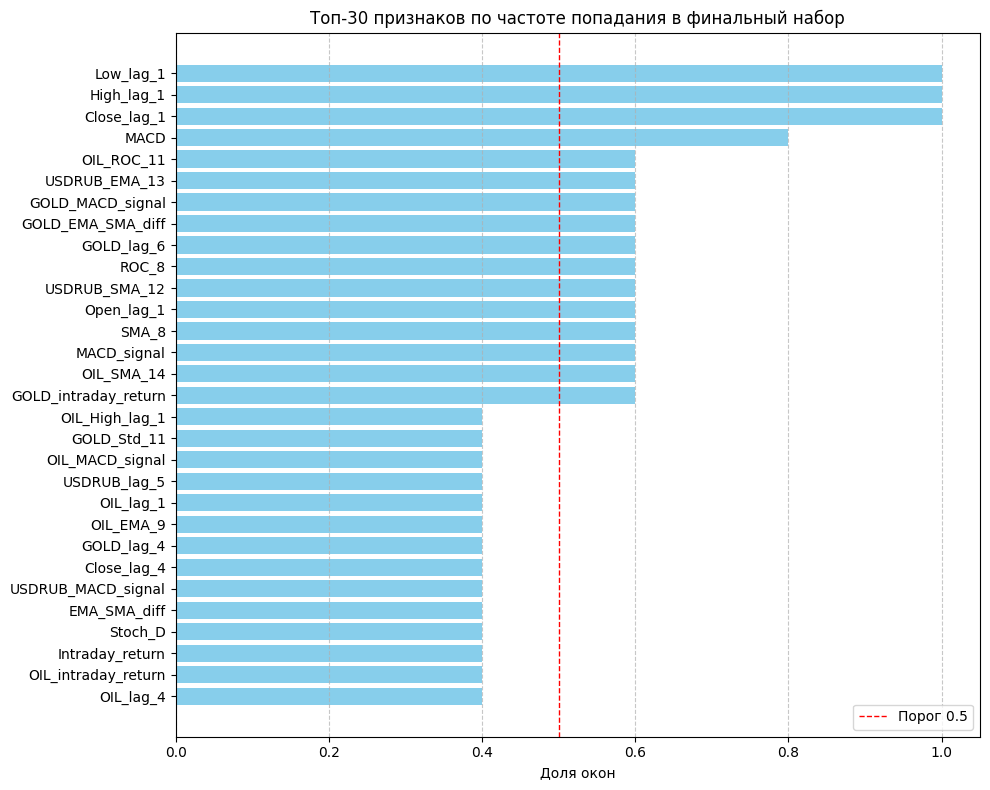

2026-03-06 18:56:15,928 - INFO - Отобрано признаков с частотой > 0.5: 16


In [26]:
result = compare_windows_selection(
    df_features=pd.concat([X_train, y_train], axis=1),
    target_col='Close',
    window_sizes=(287, 287, 287, 287, 286),
    plot=True,
    save_plot=True
)

In [27]:
stable_features = result['selected_features']
print(f"Отобрано {len(stable_features)} стабильных признаков:")
print(stable_features)
df_features = pd.concat([df_features[stable_features], y], axis=1)

Отобрано 16 стабильных признаков:
['High_lag_1', 'Close_lag_1', 'Low_lag_1', 'MACD', 'USDRUB_EMA_13', 'OIL_ROC_11', 'OIL_SMA_14', 'GOLD_intraday_return', 'MACD_signal', 'SMA_8', 'Open_lag_1', 'USDRUB_SMA_12', 'GOLD_MACD_signal', 'GOLD_EMA_SMA_diff', 'GOLD_lag_6', 'ROC_8']


In [28]:
df_features.to_parquet(DATA_PROC_DIR / 'stable_features.parquet')